# Кластерный анализ методом k-средних (k-means).

## Цель работы

Выявить структуру сходства между отсканированными изображениями цифр на основе семи бинарных признаков с помощью кластерного анализа методом k-средних (k-means). Определить оптимальное количество кластеров и провести содержательную интерпретацию полученных групп.

## Загрузка и предобработка данных

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

In [ ]:
df = pd.read_csv("digit.dat", sep=";")

In [ ]:
# посмотрим на несколько первых записей
df.head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Видим, что все столбцы признаков повторяются в данных по два раза. Проверим, действительно ли они идентичны.

In [ ]:
pairs = [('A','A2'), ('B','B2'), ('C','C2'), ('D','D2'),
         ('E','E2'), ('F','F2'), ('G','G2'), ('H','H2')]

for c1, c2 in pairs:
    a = df[c1].str.strip()
    b = df[c2].str.strip()

    equal = a.equals(b)
    print(f'{c1} vs {c2}: identical = {equal}')

A vs A2: identical = True
B vs B2: identical = True
C vs C2: identical = True
D vs D2: identical = True
E vs E2: identical = True
F vs F2: identical = True
G vs G2: identical = True
H vs H2: identical = True


Теперь удалим эти столбцы, так как они не несут никакой новой информации

In [ ]:
df = df.drop(columns=['A2', 'B2', 'C2', 'D2', 'E2', 'F2', 'G2', 'H2'])

Разделим столбцы на признаки и target (переменную в которой лежит сама цифра)

In [ ]:
target = 'A'

X = df.drop(columns=[target])
y = df[target]

In [ ]:
# интересно, что ONE написано везде с лишним пробелом
# unique() вывел бы пропуски, если бы они имелись - видим, что пропусков нет
for col in X.columns:
  print(f'{col}: {X[col].unique()}')

# лишние пробелы есть и в значениях target
print(f'\nA: {y.unique()}')

B: ['ONE ' 'ZERO']
C: ['ZERO' 'ONE ']
D: ['ONE ' 'ZERO']
E: ['ZERO' 'ONE ']
F: ['ZERO' 'ONE ']
G: ['ONE ' 'ZERO']
H: ['ZERO' 'ONE ']

A: ['seven' 'one  ' 'four ' 'two  ' 'eight' 'five ' 'six  ' 'zero ' 'nine '
 'three']


In [ ]:
X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)
y = y.str.strip()

data = pd.concat([y, X], axis=1)
data.head()

/tmp/ipykernel_5615/3387429379.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)


,A,B,C,D,E,F,G,H
0,seven,1,0,1,0,0,1,0
1,one,0,0,1,0,0,1,0
2,four,0,1,1,1,0,1,0
3,two,1,1,1,1,1,0,0
4,eight,0,1,1,1,1,1,1


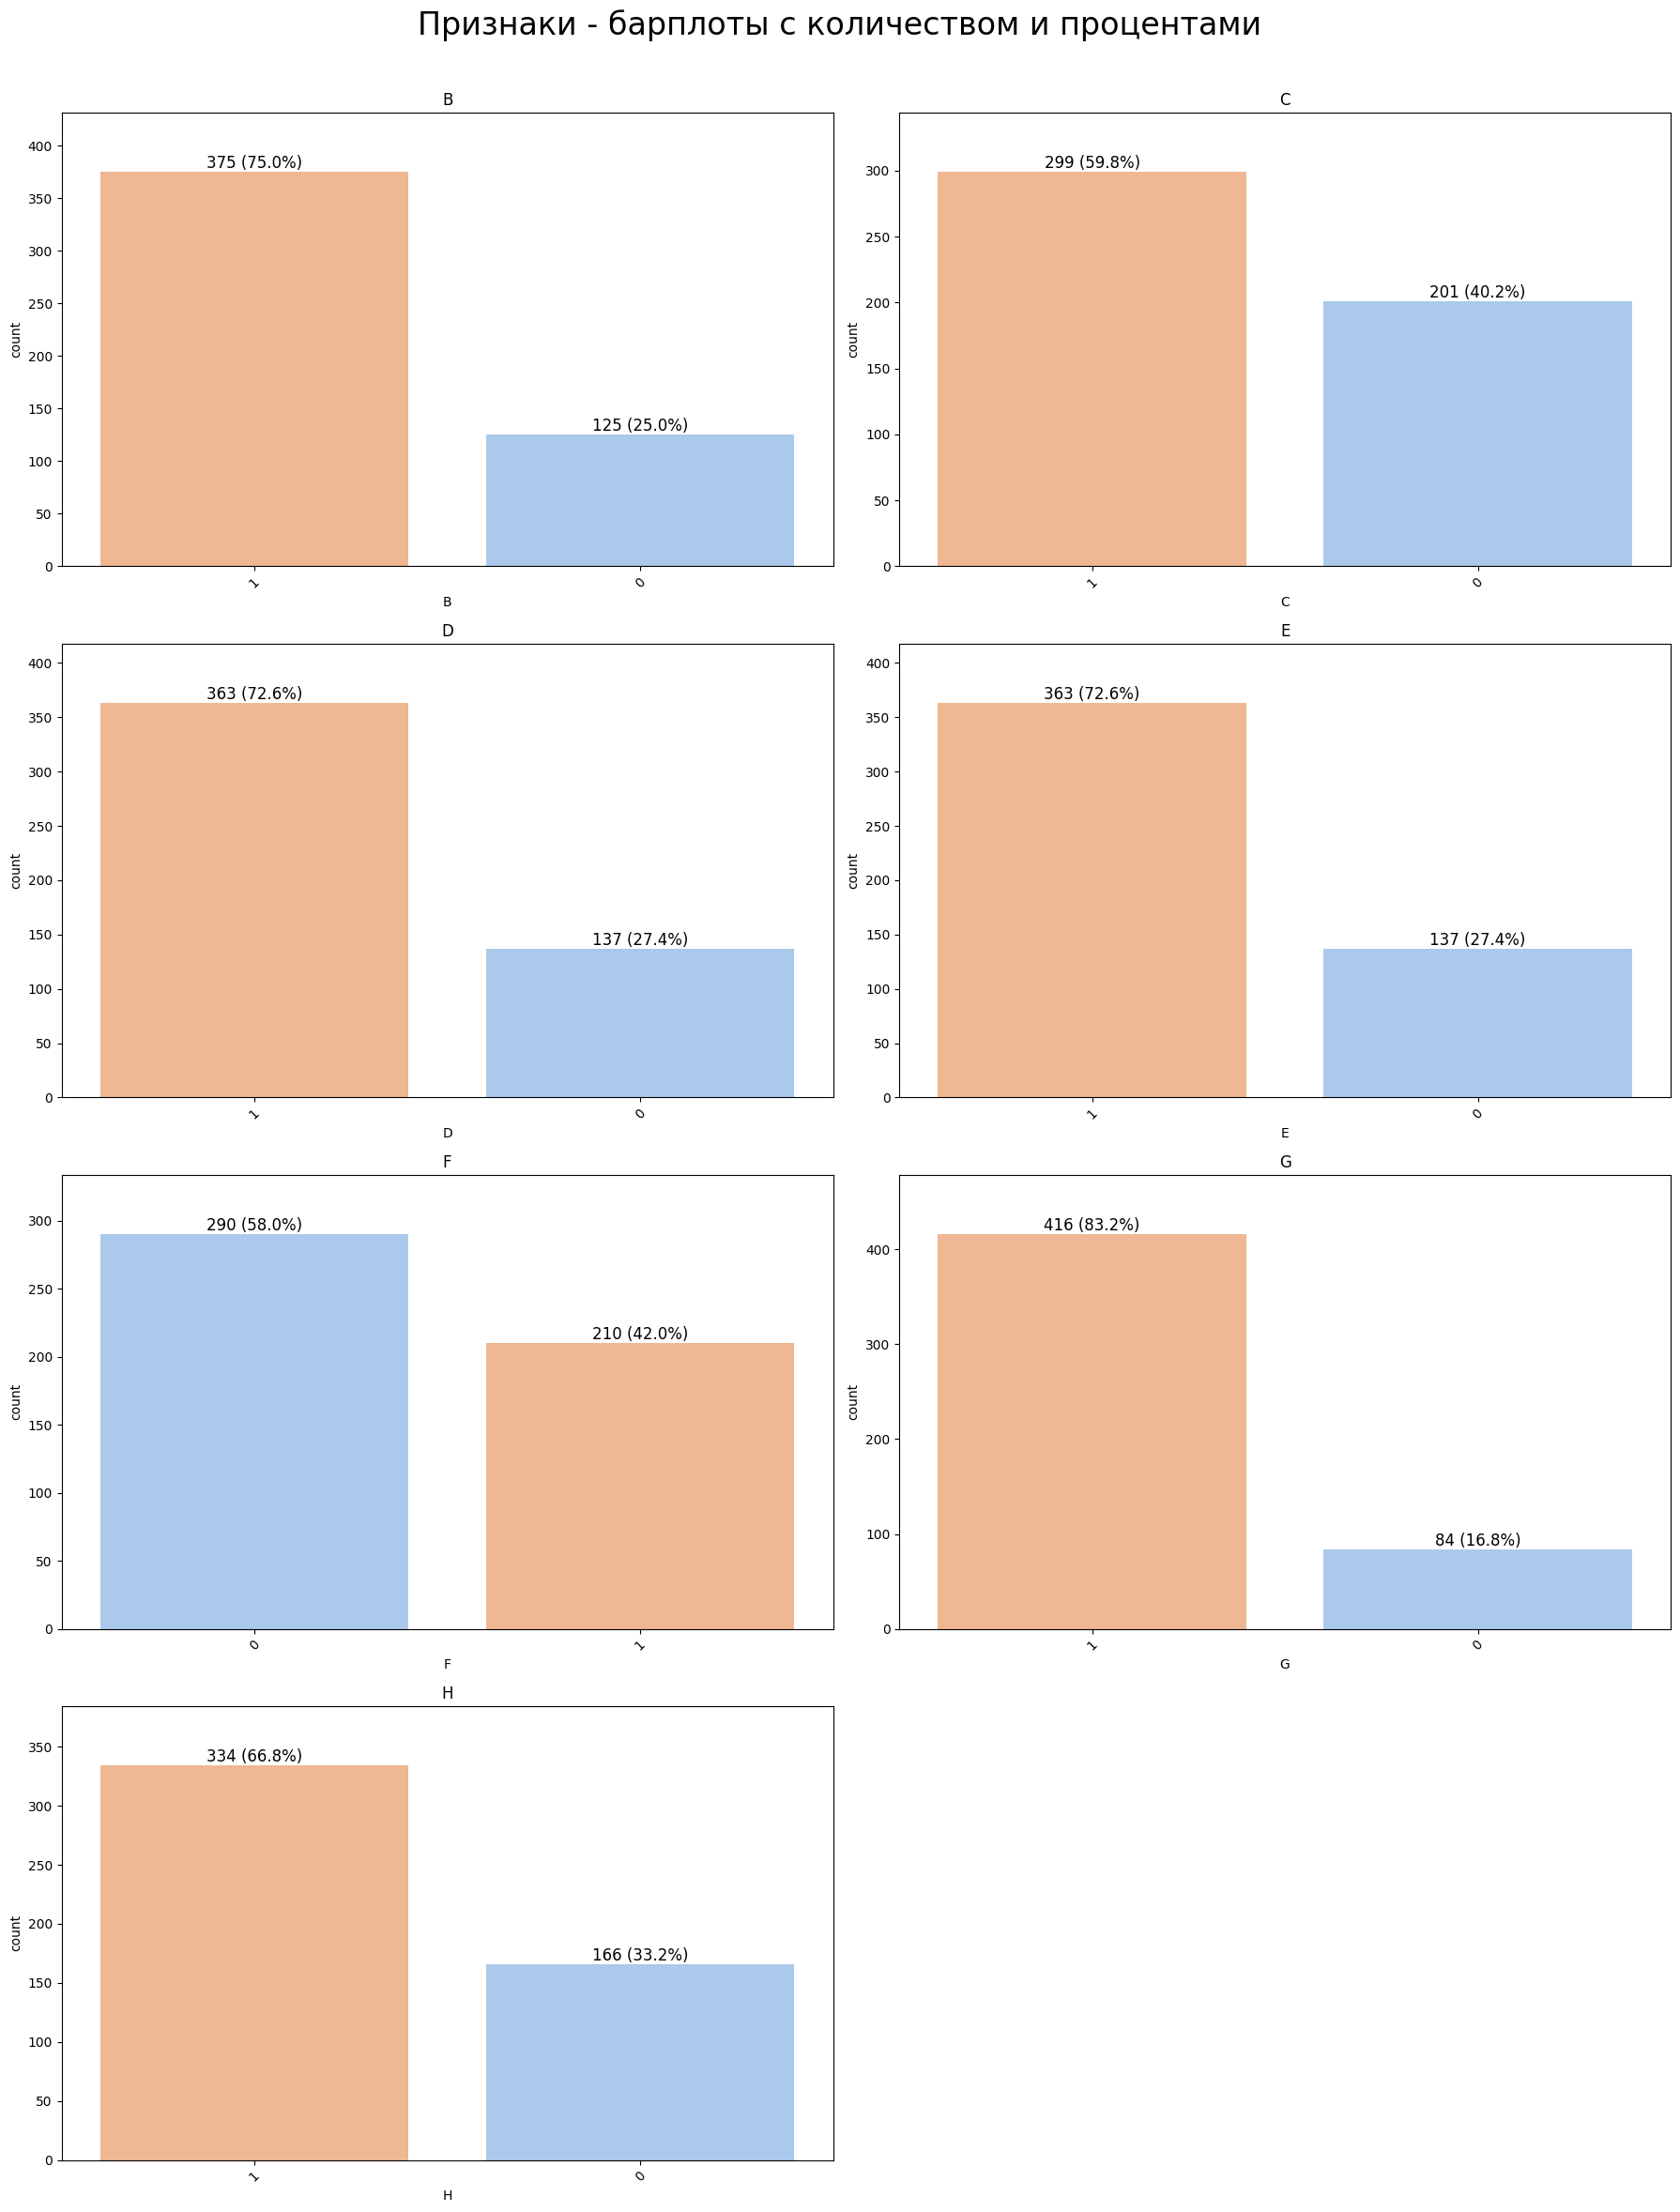

In [ ]:
columns = X.columns

n_cat = len(columns)
cols = 2
rows = math.ceil(n_cat / cols)

fig_cat, axes_cat = plt.subplots(rows, cols, figsize=(cols * 9, rows * 6))
axes_cat = axes_cat.flatten()

for i, col in enumerate(columns):
    ax = axes_cat[i]
    order = X[col].value_counts().index
    counts = X[col].value_counts()
    total = len(X)

    sns.countplot(data=X, x=col, hue=col, ax=ax, order=order, palette="pastel", legend=False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

    for p in ax.patches:
        count = int(p.get_height())
        percent = 100 * count / total
        ax.annotate(
            f"{count} ({percent:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=12,
        )
    ax.set_ylim(0, max(counts.values) * 1.15)

# Удаляем лишние оси
for j in range(i + 1, len(axes_cat)):
    fig_cat.delaxes(axes_cat[j])

fig_cat.suptitle("Признаки - барплоты с количеством и процентами", fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

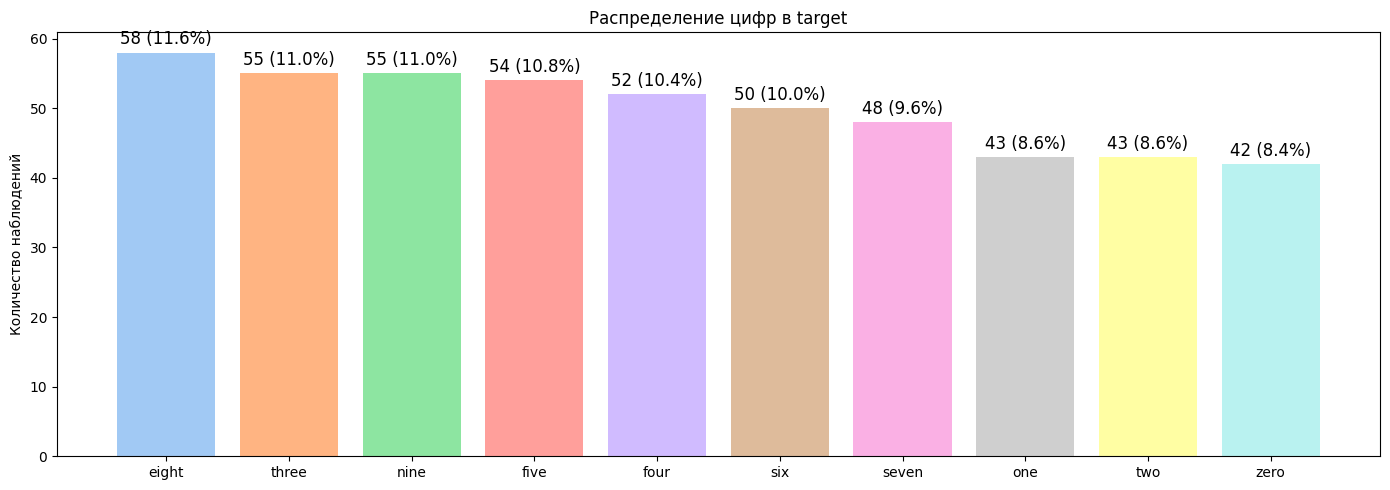

In [ ]:
counts = y.value_counts()
pct = y.value_counts(normalize=True) * 100

order = counts.sort_values(ascending=False).index
counts = counts.loc[order]
pct = pct.loc[order]

fig, ax = plt.subplots(figsize=(14, 5))
colors = sns.color_palette("pastel", n_colors=len(counts))

bars = ax.bar(counts.index.astype(str), counts.values, color=colors)

ax.set_title('Распределение цифр в target')
ax.set_ylabel('Количество наблюдений')

ax.bar_label(
    bars,
    labels=[f'{c} ({p:.1f}%)' for c, p in zip(counts.values, pct.values)],
    padding=3, fontsize=12,
)

plt.tight_layout()
plt.show()

In [ ]:
def draw_digit_on_ax(
    row_index: int,
    ax: plt.Axes,
    X: pd.DataFrame = X,
    y: pd.DataFrame = y
) -> None:
    """
    Рисует одну цифру на заданной оси по переданному индексу строки

    Параметры:
    row_index : int
        Номер строки в X и y
    ax : matplotlib.axes.Axes
        Ось, на которой выполняется отрисовка
    X : pd.DataFrame
        DataFrame с колонками B–H
    y : pd.DataFrame
        DataFrame с колонкой A
    """
    if row_index >= len(df):
        print(f"Ошибка: индекс {row_index} выходит за пределы DataFrame")
        return

    row = X.iloc[row_index].copy()
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.axis('off')
    ax.set_title(f'Объект {row_index}, цифра {y.iloc[row_index]}', fontsize=14)

    segments = [
        (row['B'], [0.25, 0.75], [1.0, 1.0]),
        (row['C'], [0.25, 0.25], [0.5, 1.0]),
        (row['D'], [0.75, 0.75], [0.5, 1.0]),
        (row['E'], [0.25, 0.75], [0.5, 0.5]),
        (row['F'], [0.25, 0.25], [0.0, 0.5]),
        (row['G'], [0.75, 0.75], [0.0, 0.5]),
        (row['H'], [0.25, 0.75], [0.0, 0.0]),
    ]

    for on, xs, ys in segments:
        ax.plot(xs, ys, color='black' if on == 1 else 'white')

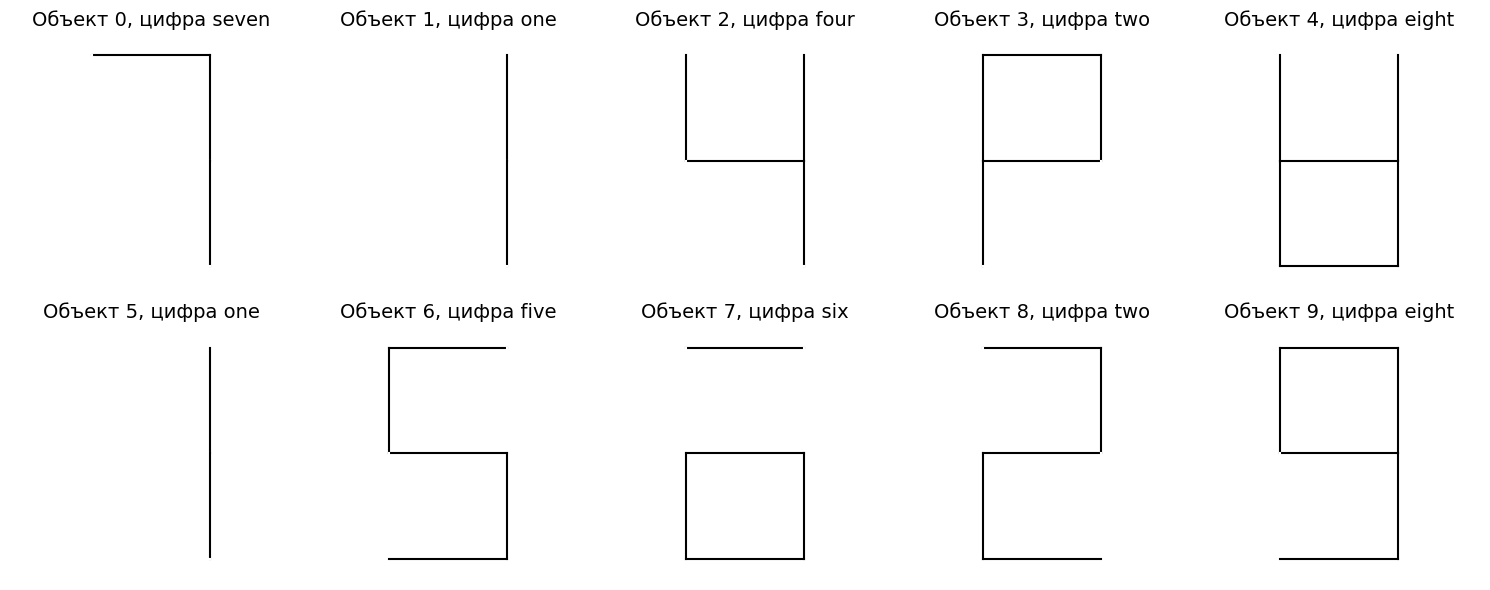

In [ ]:
n = 10
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i in range(n):
    draw_digit_on_ax(i, axes[i])

plt.tight_layout()
plt.show()

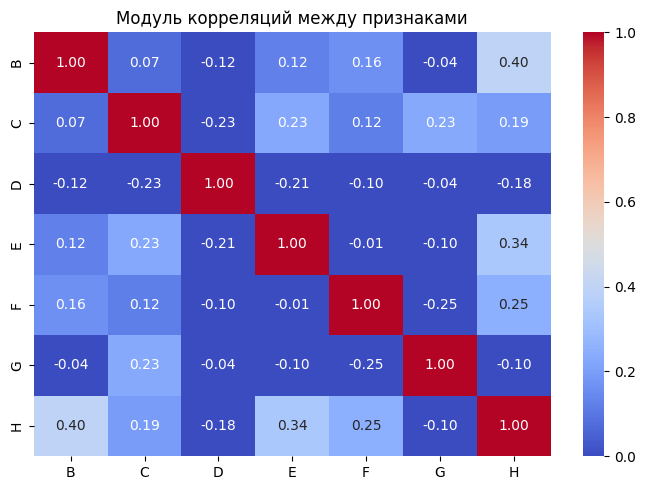

In [ ]:
corr_matrix = X.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=0, vmax=1,
    square=False,
    fmt='.2f'
)

plt.title("Модуль корреляций между признаками")
plt.tight_layout()
plt.show()

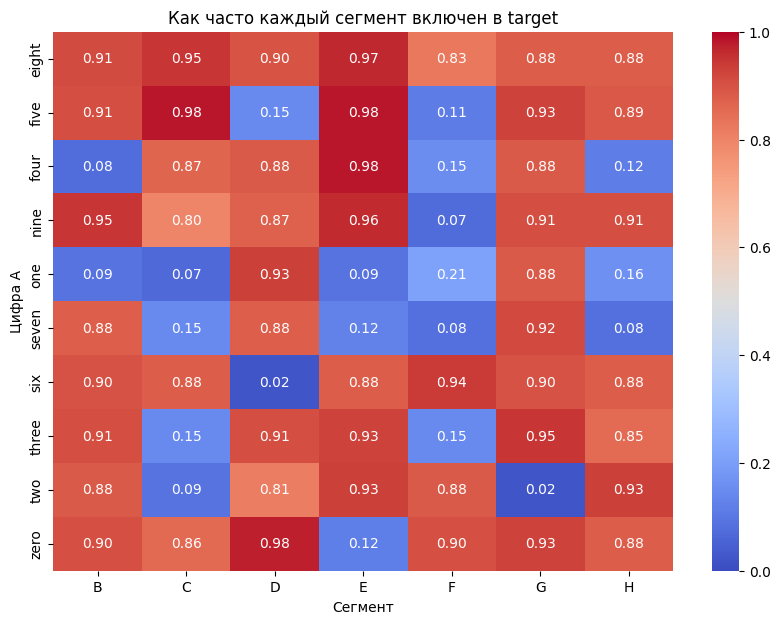

In [ ]:
segments = X.columns

profiles = data.groupby('A')[segments].apply(
    lambda x: (x == 1).mean()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    profiles,
    annot=True,
    cmap='coolwarm',
    vmin=0,
    vmax=1,
    fmt='.2f'
)

plt.xlabel('Сегмент')
plt.ylabel('Цифра A')
plt.title('Как часто каждый сегмент включен в target')
plt.show()

Проведенный разведочный анализ показал, что данные хорошо структурированы и вполне пригодны для иерархической кластеризации, но имеют ряд особенностей, которые необходимо учитывать при выборе метрик.

Распределение признаков (B–H) показывают умеренную или высокую долю единиц. Особенно выделяется сегмент G (нижний правый вертикальный): он равен 1 в 83% наблюдений. Его дисперсия минимальна, поэтому вклад в различение объектов будет небольшим. Остальные сегменты более информативны.

Распределение цифр (переменная A) достаточно сбалансировано: частоты лежат в узком диапазоне от 8,4 % (zero) до 11,6 % (eight). Сильного перекоса нет, поэтому размеры кластеров в дальнейшем не будут сильно искажены частотой отдельных цифр. Это упрощает интерпретацию — если какой-то кластер окажется заметно больше остальных, это скорее отразит реальную схожесть паттернов, а не артефакт несбалансированности.

Графику, показывающий то, как часто сегменты входят в ту или иную цифру из target, доказывает, что в данных есть неправильно отсканированные цифры.

Матрица корреляций (модули) показывает, что сегменты в целом слабо связаны друг с другом. Самые заметные связи — B–H (0,40) и E–H (0,34), остальные значительно ниже. Сильной мультиколлинеарности нет. В связи с этим можно использовать обычные бинарные меры расстояния, не опасаясь сильного искажения из-за зависимых признаков. В то же время наличие даже умеренных корреляций делает чисто евклидово расстояние менее предпочтительным — оно будет частично дублировать информацию.

## Выбор оптимального числа кластеров

Оба метода (Elbow и Silhouette) не показали однозначного оптимума: инерция снижалась плавно, а Silhouette score монотонно возрастал с ростом числа кластеров. Такое поведение типично для бинарных данных с большим количеством дубликатов и использованием евклидова расстояния.

В качестве компромиссного решения было выбрано k = 10, так как:
- после этого значения рост Silhouette замедляется;
- на графике инерции наблюдается слабое изменение наклона в районе 8–10 кластеров.

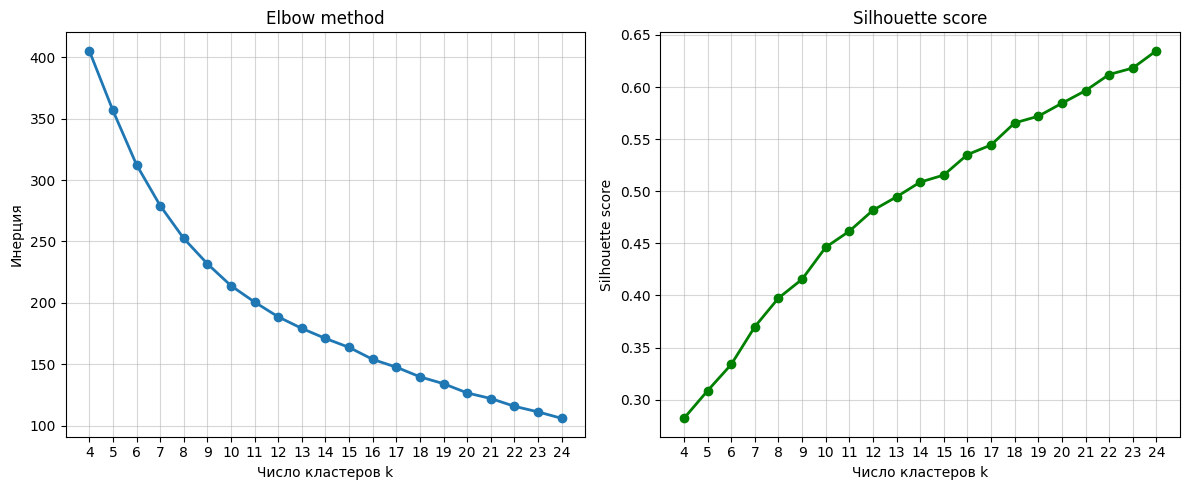

In [ ]:
inertias = []
silhouettes = []
K_range = range(4, 25)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=100)
    labels = kmeans.fit_predict(X)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertias, 'o-', linewidth=2)
plt.xlabel('Число кластеров k')
plt.ylabel('Инерция')
plt.title('Elbow method')
plt.xticks(K_range)
plt.grid(True, alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouettes, 'o-', color='green', linewidth=2)
plt.xlabel('Число кластеров k')
plt.ylabel('Silhouette score')
plt.title('Silhouette score')
plt.xticks(K_range)
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

## Кластеризация K-Means

In [18]:
kmeans = KMeans(n_clusters=10, random_state=42, n_init=100)
labels_kmeans = kmeans.fit_predict(X)

In [19]:
ct = pd.crosstab(
    labels_kmeans,
    y,
    rownames=['Кластер'],
    colnames=['Цифра'],
    margins=True,
    margins_name='Всего',
)

print(ct)

Цифра    eight  five  four  nine  one  seven  six  three  two  zero  Всего
Кластер                                                                   
0            0     0    41     3    3      0    0      0    0     0     47
1            2     0     0     2    0      1    6      1    1    34     47
2            2     1     4     4    4     38    0      8    0     2     63
3            5     4     3     1    0      0   40      0    1     0     54
4            1     1     1    10    1      2    1     33    5     0     55
5            1     0     1     0   35      6    0      0    0     1     44
6            0     0     2     1    0      1    0      0   34     1     39
7            1    41     0     3    0      0    2      2    0     0     49
8            6     5     0    30    0      0    0      5    0     1     47
9           40     2     0     1    0      0    1      6    2     3     55
Всего       58    54    52    55   43     48   50     55   43    42    500


Видно что кластеры очень хорошо разделили цифры - каждый кластер примерно соответствует своей цифре

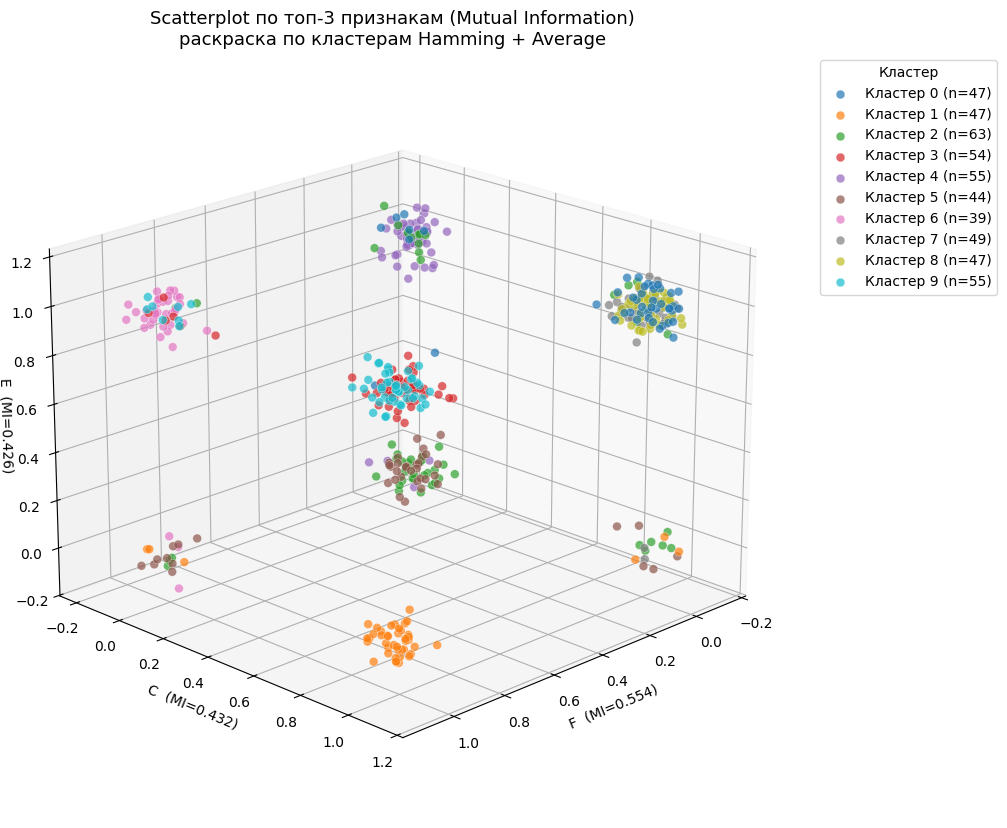

In [29]:
mi = mutual_info_classif(X, labels_kmeans, discrete_features=True)
mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
top3 = mi_series.head(3).index.tolist()

rng = np.random.default_rng(42)
jitter = 0.05

df_plot = pd.DataFrame({
    top3[0]: X[top3[0]].astype(float).values + rng.normal(0, jitter, len(X)),
    top3[1]: X[top3[1]].astype(float).values + rng.normal(0, jitter, len(X)),
    top3[2]: X[top3[2]].astype(float).values + rng.normal(0, jitter, len(X)),
    'cluster': np.asarray(labels_kmeans).astype(str),
})

fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection='3d')

palette = sns.color_palette('tab10', n_colors=df_plot['cluster'].nunique())

for (name, group), color in zip(df_plot.groupby('cluster'), palette):
    ax.scatter(
        group[top3[0]], group[top3[1]], group[top3[2]],
        s=40, alpha=0.7, color=color,
        label=f'Кластер {name} (n={len(group)})',
        edgecolors='white', linewidths=0.3,
    )

ax.set_title('Scatterplot по топ-3 признакам (Mutual Information)\nраскраска по кластерам Hamming + Average',
             fontsize=13)
ax.set_xlabel(f'{top3[0]}  (MI={mi_series[top3[0]]:.3f})')
ax.set_ylabel(f'{top3[1]}  (MI={mi_series[top3[1]]:.3f})')
ax.set_zlabel(f'{top3[2]}  (MI={mi_series[top3[2]]:.3f})', labelpad=-1)
ax.legend(title='Кластер', loc='upper left', bbox_to_anchor=(1.05, 1))
ax.view_init(elev=20, azim=45)

fig.subplots_adjust(left=0.05, right=0.85, top=0.90, bottom=0.05)
plt.show()

In [32]:
def evaluate_clustering(X: pd.DataFrame,
                        labels: np.ndarray,
                        y_true: pd.DataFrame,
                        metric_for_silhouette: str,
                        name: str) -> pd.Series:
    """
    Считает набор метрик качества кластеризации и возвращает их одной строкой.

    Параметры:
    X: pd.DataFrame
        DataFrame с колонками B–H
    labels: np.ndarray
        Метки кластера
    y_true:pd.DataFrame
        DataFrame с колонкой A
    metric_for_silhouette: str
        Метрика, используемая для расчета silhouette
    name: str, default="Clustering"
        Имя строки результата — попадет в Series.name

    Возвращает
    pd.Series
        pd.Series со значениями метрик
    """

    results = {}

    results['Silhouette'] = silhouette_score(X, labels, metric=metric_for_silhouette)
    results['ARI'] = adjusted_rand_score(y_true, labels)
    results['NMI'] = normalized_mutual_info_score(y_true, labels)

    return pd.Series(results, name=name)

res_ham = evaluate_clustering(
    X, labels_kmeans, y_true=y,
    metric_for_silhouette='hamming',
    name='Hamming + Average'
)

res_ham

,Hamming + Average
Silhouette,0.494596
ARI,0.497386
NMI,0.588097


## Вывод

K-Means смог довольно успешно отделить большинство цифр друг от друга.
Наиболее чистые кластеры — 4, 2, 5, 1, 0.

Наибольшее смешение наблюдается у визуально похожих цифр:
- 3 - 9 - 8
- 7 - 1 (небольшое)
- 6 - 5 (небольшое)

Визуализация Scatterplot по трем наиболее информативным признакам (C, F, E) показывает, что кластеры занимают разные области пространства. Большинство групп образуют компактные облака, что подтверждает относительно хорошее качество разделения. Полного отсутствия перекрытий нет (особенно в центре), что согласуется с умеренными значениями метрик.

K-Means с 10 кластерами дал более интерпритируемый и качественный результат, чем иерархическая кластеризация. Алгоритм смог выделить группы, в большинстве случаев соответствующие отдельным цифрам, несмотря на сильные искажения изображений и бинарный характер признаков. Ограничения результата связаны в первую очередь с природой данных: семь бинарных сегментов не всегда позволяют однозначно отличить похожие цифры (особенно 3-8-9), а евклидово расстояние, используемое в K-Means, не является оптимальным для бинарных векторов.